# DSCI 552 - Homework 5

## Jazmine Tabora

## 1. Decision Trees as Interpretable Models

### (a) Download the Accute Inflamations data

### (b) Build a decision tree on the whole data set and plot it.

In [6]:
import pandas as pd

In [7]:
data = pd.read_csv("diagnosis.data", sep="\t", header=None, encoding="utf-16", decimal=",")

data.columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "bladder_inflammation",
    "nephritis"
]

data_clean = data.copy() # copy so the original data is not modified

symptom_columns = [
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning"
]

for column in symptom_columns:
    data_clean[column] = data_clean[column].map({"no": 0, "yes": 1})

# Combining the two diagnoses into one label
data_clean["diagnosis"] = (
    data_clean["bladder_inflammation"] + "_" + data_clean["nephritis"])

In [9]:
# Features and labels
feature_columns = ["temperature"] + symptom_columns
X = data_clean[feature_columns]
y = data_clean["diagnosis"]

print(data_clean.shape)
print(y.value_counts())

(120, 9)
diagnosis
yes_no     40
no_yes     31
no_no      30
yes_yes    19
Name: count, dtype: int64


In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

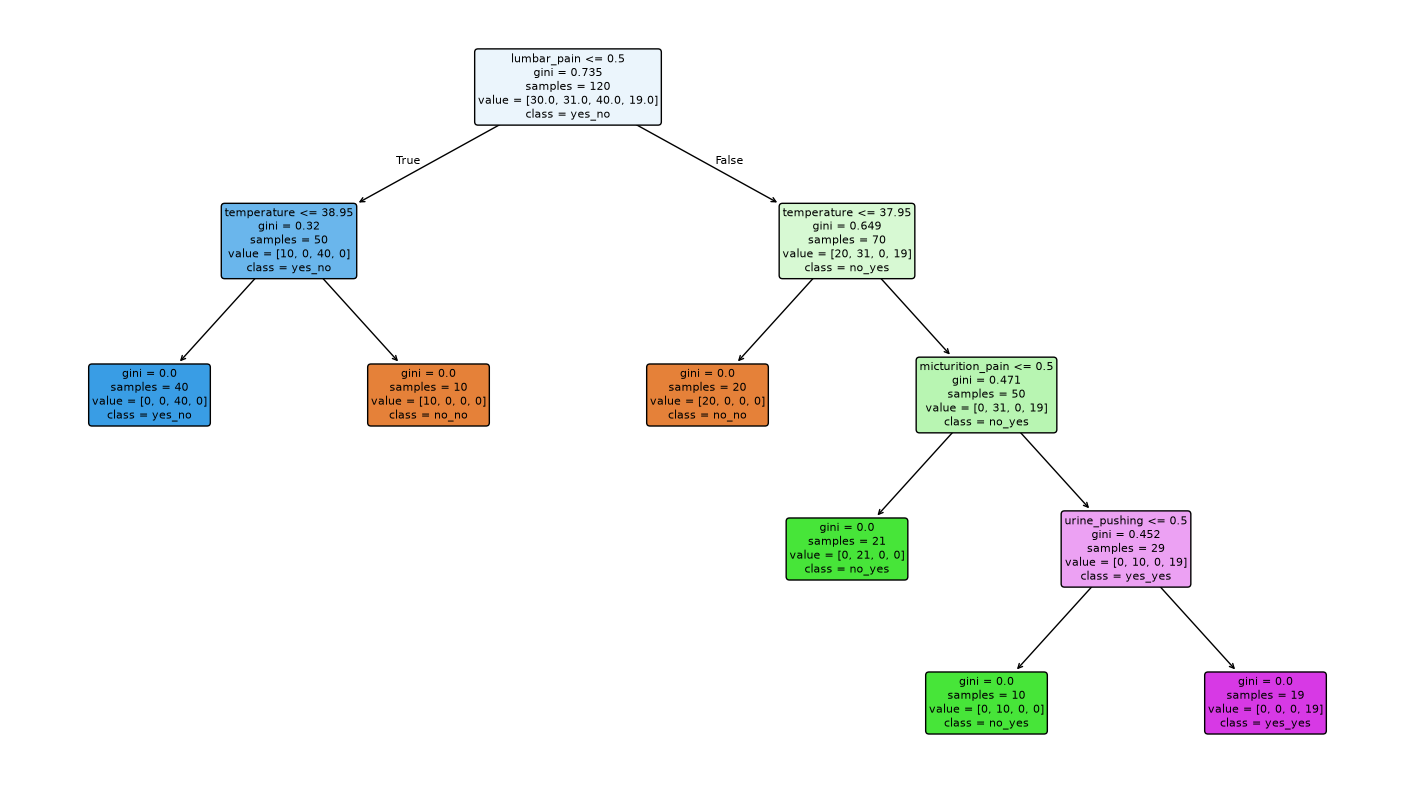

In [11]:
# Decision Tree Model
tree_model = DecisionTreeClassifier(random_state=0)
tree_model.fit(X, y)

plt.figure(figsize=(18, 10))

plot_tree(
    tree_model,
    feature_names=feature_columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

### (c) Convert the decision rules into a set of IF-THEN rules.

#### ANSWER
* If the lumber_pain is No and temperature is $\leq$ 38.95, then predict bladder inflamaation = Yes and nephritis = No
* If lumbar_pain is No and temperature > 38.95, then predict bladder inflammation = No and nephritis = No
* If lumbar_pain is Yes and temperature $\leq$ 37.95, then predict bladder,inflammation = No and nephritis = No
* If lumbar_pain is Yes and temperature > 37.95 and micturition_pain is No, then predict bladder inflammation = No and nephritis = Yes
* If lumbar_pain is Yes and temperature > 37.95 and micturition_pain is Yes and urine_pushing is No, then predict bladder inflammation = No and nephritis = Yes
* If lumbar_pain is Yes and temperature > 37.95 and micturition_pain is Yes and urine_pushing is Yes, then predict bladder inflammation = Yes and nephritis = Yes

### (d) Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

In [12]:
# Alpha values
pruning_path = tree_model.cost_complexity_pruning_path(X, y)
alpha_values = pruning_path.ccp_alphas

# Fitting a tree at each alpha
# Recording size and accuracy
pruning_results = []

for alpha in alpha_values:
    pruned_tree = DecisionTreeClassifier(
        random_state = 0,
        ccp_alpha = alpha
    )
    
    pruned_tree.fit(X, y)
    
    pruning_results.append({
        "alpha": alpha,
        "number_of_leaves": pruned_tree.get_n_leaves(),
        "tree_depth": pruned_tree.get_depth(),
        "training_accuracy": pruned_tree.score(X, y)
    })

pruning_table = pd.DataFrame(pruning_results)
pruning_table

,alpha,number_of_leaves,tree_depth,training_accuracy
0,0.000000,6,4,1.000000
1,0.098167,4,2,0.841667
2,0.133333,3,2,0.758333
3,0.182000,2,1,0.591667
4,0.222917,1,0,0.333333


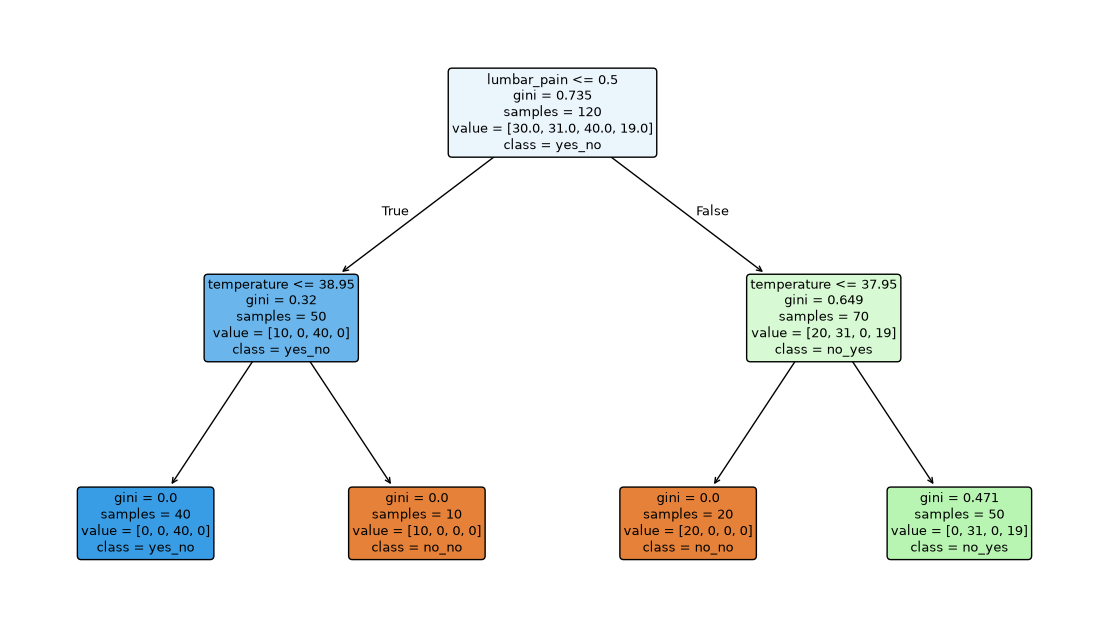

Chosen alpha: 0.09816666666666667
Number of leaves: 4
Training accuracy: 0.8416666666666667


In [14]:
# Alpha for a 4-leaf tree
chosen_alpha = pruning_table.loc[1, "alpha"]

# Pruned tree
pruned_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=chosen_alpha)
pruned_tree.fit(X, y)

plt.figure(figsize=(14, 8))
plot_tree(
    pruned_tree,
    feature_names=feature_columns,
    class_names=pruned_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

print("Chosen alpha:", chosen_alpha)
print("Number of leaves:", pruned_tree.get_n_leaves())
print("Training accuracy:", pruned_tree.score(X, y))

#### ANSWER
* If lumbar pain is No and temperature $\leq$ 38.95, then predict bladder inflammation = Yes and nephritis = No
* If lumbar pain is No and temperature > 38.95, then predict bladder inflammation = No and nephritis = No
* If lumbar pain is Yes and temperature $\leq$ 37.95, then predict bladder inflammation = No and nephritis = No
* If lumbar pain is Yes and temperature > 37.95, then predict bladder inflammation = No and nephritis = Yes

## 2. The LASSO and Boosting for Regression

### (a) Download the Communities and Crime data. Use the first 1495 rows of data as the training set and the rest as the test set.

In [15]:
column_names = []

with open("communities.names", "r") as file:
    for line in file:
        if line.strip().startswith("@attribute"):
            column_names.append(line.split()[1])

# Loading data 
communities = pd.read_csv(
    "communities.data",
    header=None,
    names=column_names,
    na_values="?"
)

# First 1,495 rows for training and remaining rows for testing
train_data = communities.iloc[:1495].copy()
test_data = communities.iloc[1495:].copy()

print("Full data shape:", communities.shape)
print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

Full data shape: (1994, 128)
Training data shape: (1495, 128)
Test data shape: (499, 128)


### (b) The data set has missing values. Use a data imputation technique to deal with the missing values in the data set. The data description mentions some features are nonpredictive. Ignore those features

In [16]:
# Columns that should NOT be used as predictors
non_predictive_columns = ["state", "county", "community", "communityname", "fold"]

# Value we want to predict
target_column = "ViolentCrimesPerPop"

# Separating predictors (X) from target (y)
# Training data
X_train = train_data.drop(
    columns=non_predictive_columns + [target_column]
)
y_train = train_data[target_column]
# Test data
X_test = test_data.drop(
    columns=non_predictive_columns + [target_column]
)
y_test = test_data[target_column]

# Median of each feature using training data
train_medians = X_train.median()

# Filling in missing feature values in both sets
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# Checking to see if it no longer has missing values
print("Missing values in training predictors:", X_train.isna().sum().sum())
print("Missing values in test predictors:", X_test.isna().sum().sum())
print("Missing values in training target:", y_train.isna().sum())
print("Missing values in test target:", y_test.isna().sum())

Missing values in training predictors: 0
Missing values in test predictors: 0
Missing values in training target: 0
Missing values in test target: 0


##### no more missing values!

### (c) Plot a correlation matrix for the features in the data set.

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

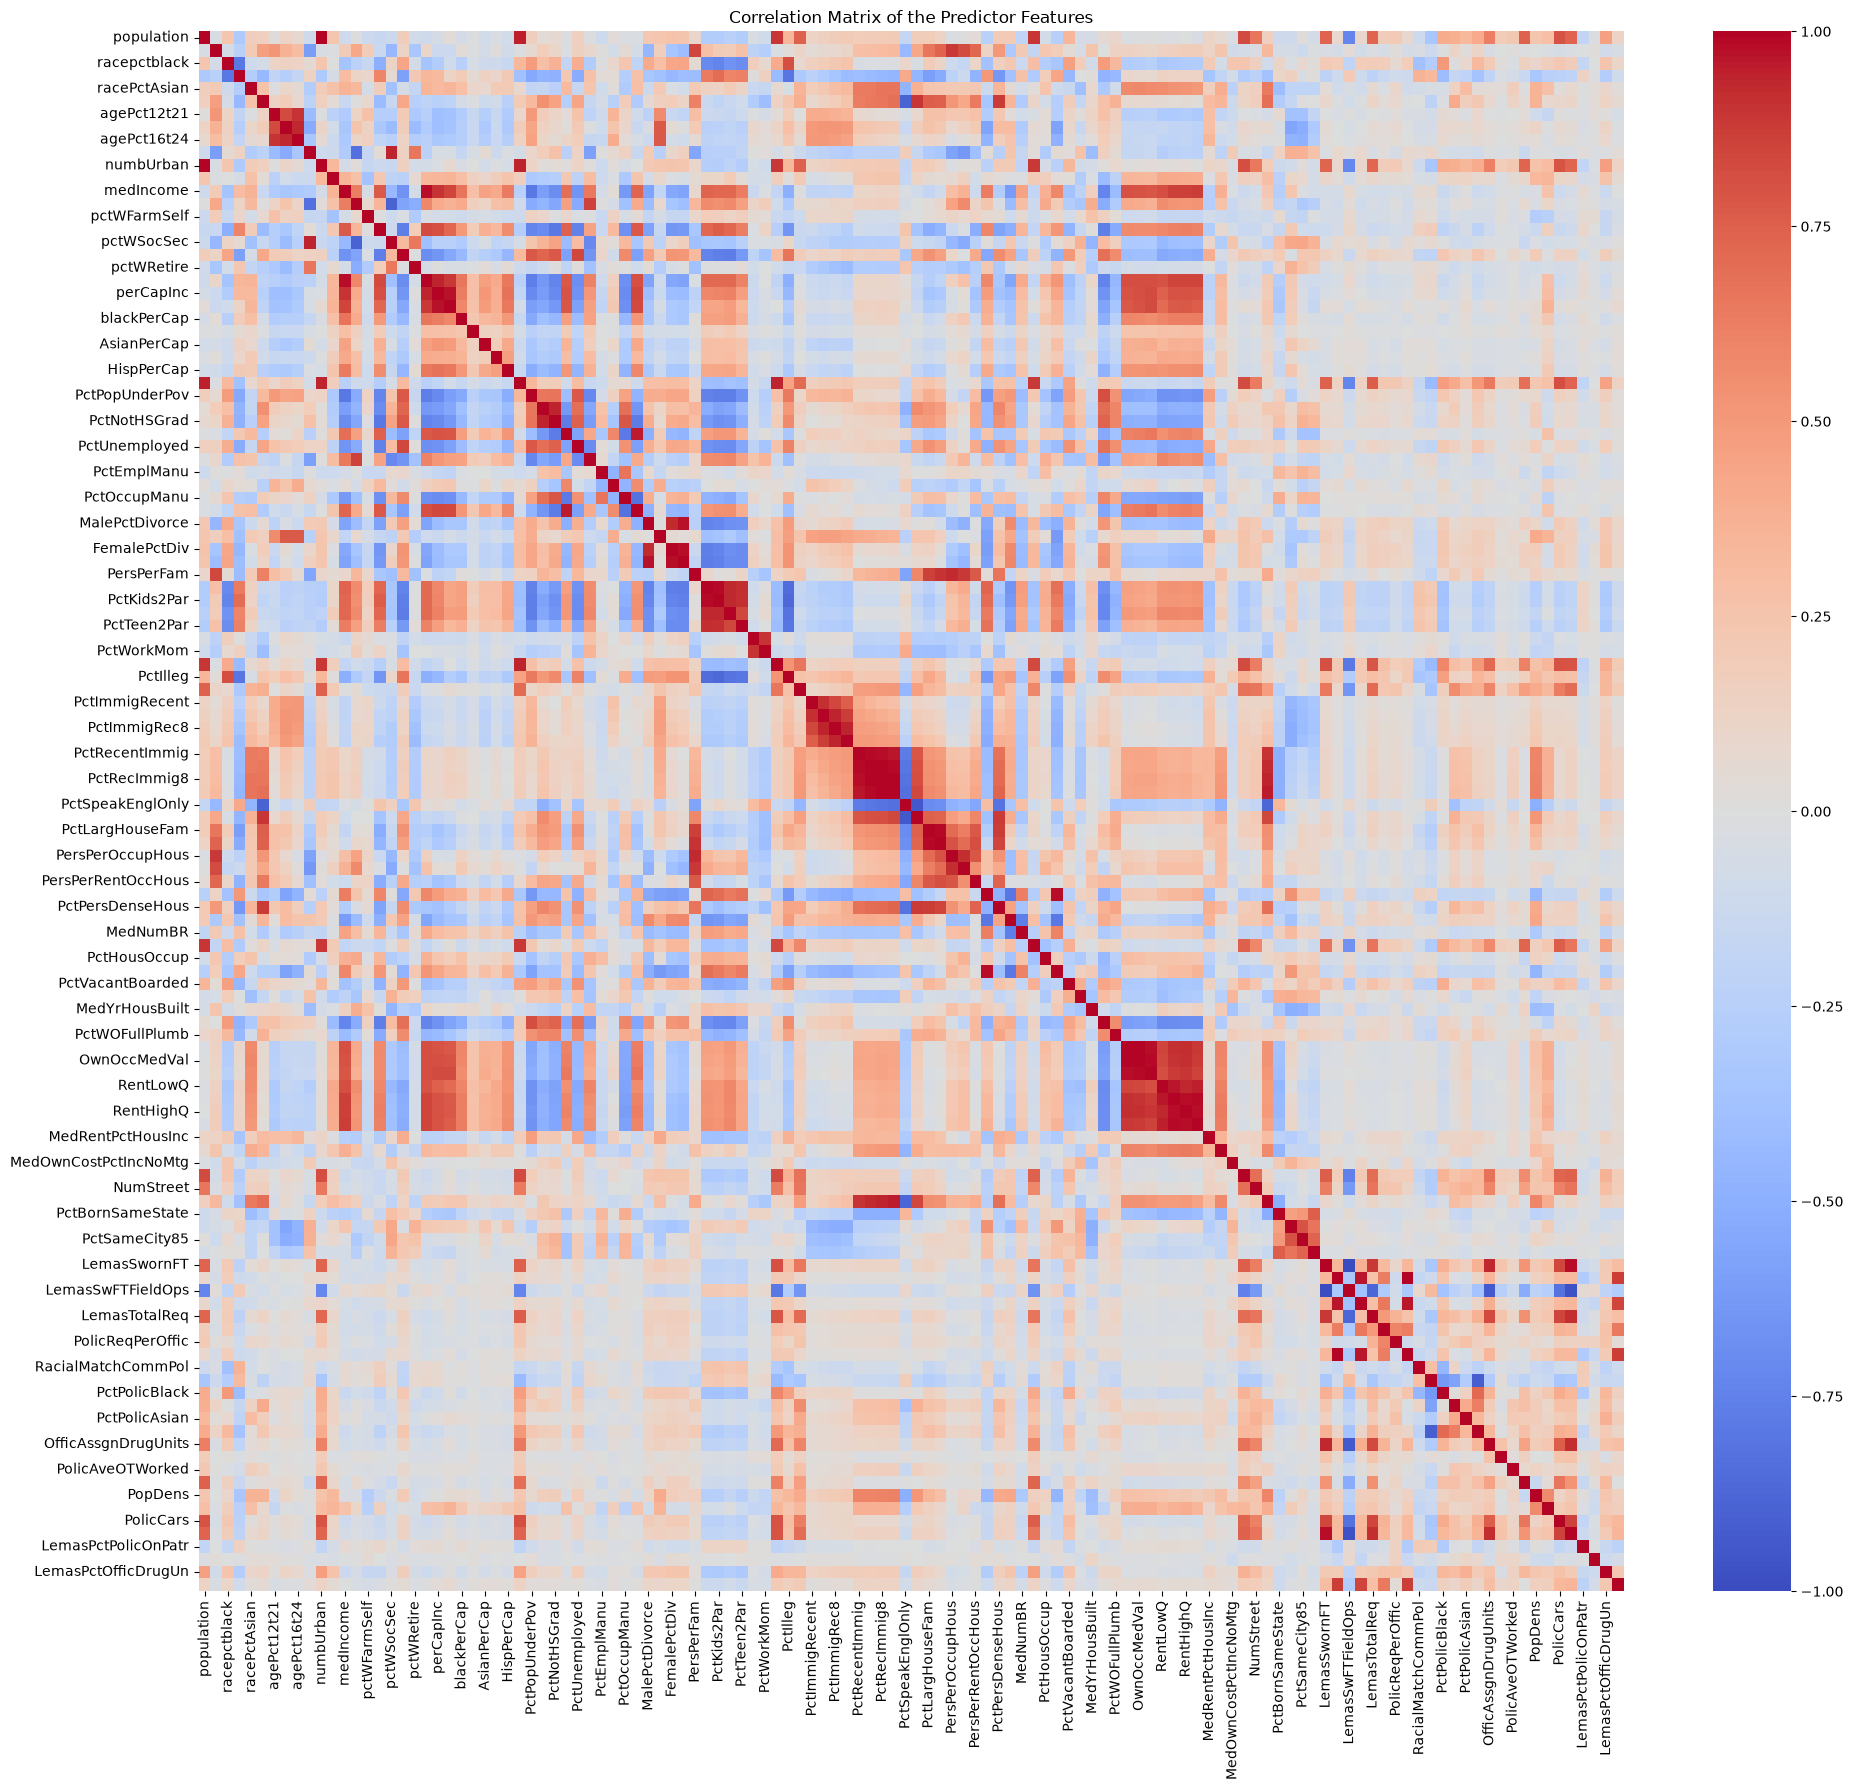

In [18]:
# Calculating correlations b/t predictor features
correlation_matrix = X_train.corr()

# Correlation matrix
plt.figure(figsize=(20, 18))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of the Predictor Features")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV for each feature, where CV = s/m, in which s is sample standard deviation and m is sample mean.

In [19]:
# Mean and sample SD for each feature, CV = sample SD / mean
feature_means = X_train.mean()
feature_std = X_train.std()
cv_values = feature_std / feature_means

# Table sorted from highest CV to lowest CV
cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_std,
    "CV": cv_values
}).sort_values("CV", ascending=False)

cv_table

,mean,sample_std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


### (e) Pick √128 features with highest CV, and make scatter plots and box plots for them. Can you draw conclusions about significance of those features just by the scatter plots?

In [20]:
import numpy as np

In [21]:
# Square root of 128 is about 11.31 so I selected 11 features with the highest CV
number_of_features = int(np.sqrt(128))
top_features = cv_table.head(number_of_features).index.tolist()

print(top_features)

['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


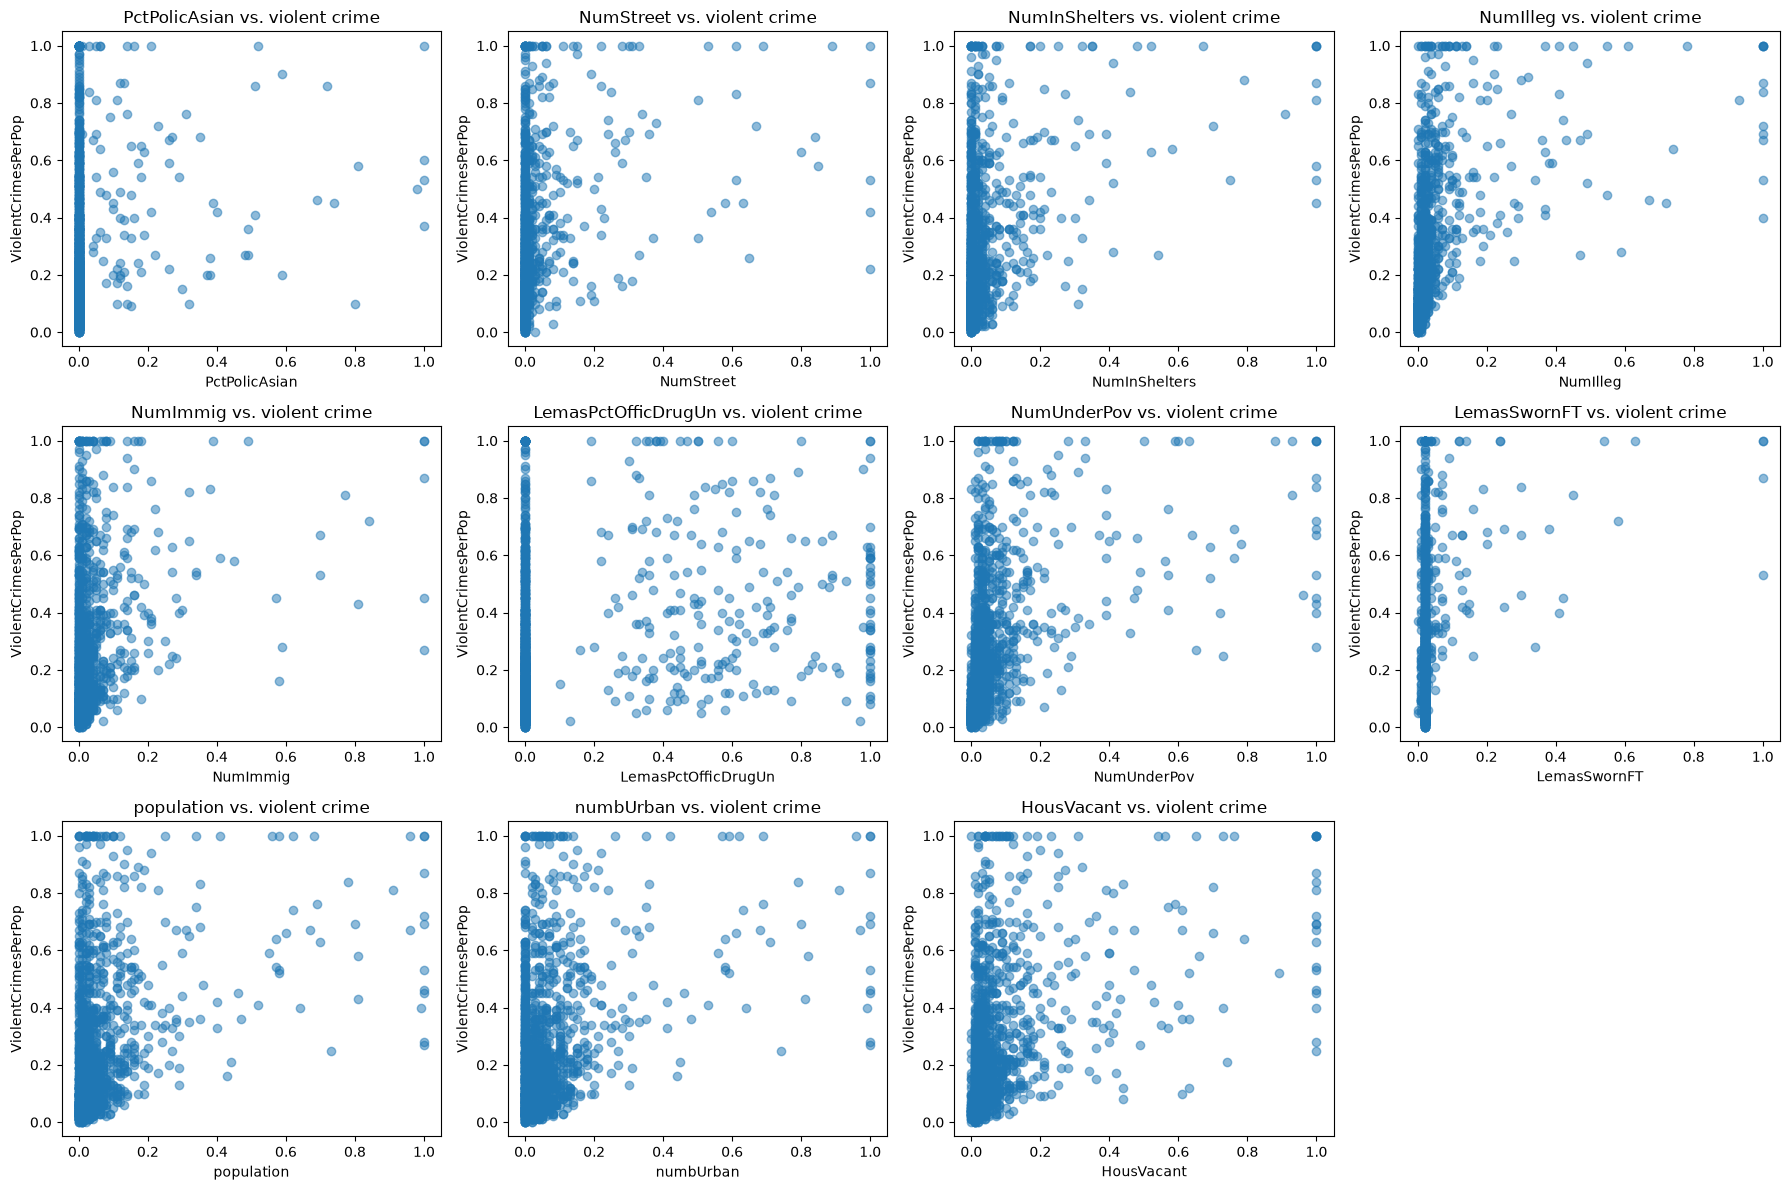

In [22]:
# One scatterplot per selected feature
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(X_train[feature], y_train, alpha=0.5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")
    axes[i].set_title(feature + " vs. violent crime")

# Removing unused space in 3-by-4 layout
for i in range(len(top_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

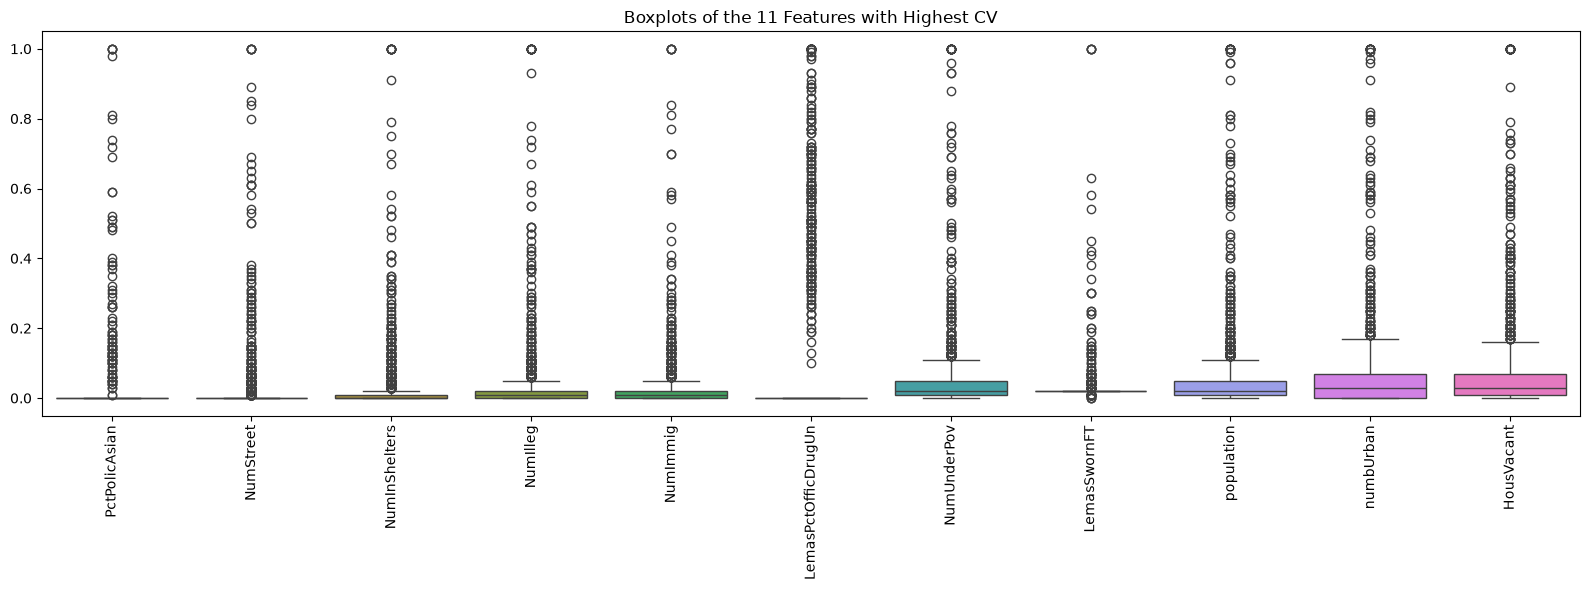

In [23]:
# Boxplots
plt.figure(figsize=(16, 6))
sns.boxplot(data=X_train[top_features])

plt.title("Boxplots of the 11 Features with Highest CV")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### ANSWER
From just the scatterplots, there seems to a possible relationship but no statistical significance is established. The plots show many points that are clustered near zero but there seems to be no clear pattern for every feature. Also, since these features have the highest CV which measurres variability relative to the mean, there doesn't seem to show that the features are significantly related to violent crime.

### (f) Fit a linear model using least squares to the training set and report the test error

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [25]:
# Least-squares linear regression model on training data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predicting violent crime values for test data
test_predictions = linear_model.predict(X_test)

# Test mean squared error
test_mse = mean_squared_error(y_test, test_predictions)

print("Test MSE:", test_mse)

Test MSE: 0.017966215426067335


### (g) Fit a ridge regression model on the training set, with λ chosen by cross-validation. Report the test error obtained.

In [26]:
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

In [27]:
# Five shuffled folds for cross-validation
cv_folds = KFold(n_splits=5, shuffle=True, random_state=0)

# Alpha with the lowest cross-validation MSE
alpha_values = np.logspace(-4, 4, 50)
ridge_model = RidgeCV(
    alphas=alpha_values,
    cv=cv_folds,
    scoring="neg_mean_squared_error"
)

# Ridge regression on training data
ridge_model.fit(X_train, y_train)

# Predict using test data
ridge_predictions = ridge_model.predict(X_test)

# Calculating test MSE
ridge_test_mse = mean_squared_error(y_test, ridge_predictions)

print("Chosen alpha:", ridge_model.alpha_)
print("Test MSE:", ridge_test_mse)

Chosen alpha: 2.559547922699533
Test MSE: 0.017503629770662943


##### test MSE is slightly lower than the least-squares MSE

### (h) Fit a LASSO model on the training set, with λ chosen by cross-validation. Report the test error obtained, along with a list of the variables selected by the model. Repeat with standardized 4 features. Report the test error for both cases and compare them

In [28]:
from sklearn.linear_model import LassoCV

In [31]:
# LASSO on training data
lasso_model = LassoCV(
    cv=cv_folds,
    max_iter=100000
)
lasso_model.fit(X_train, y_train)

# Predicting test values
lasso_predictions = lasso_model.predict(X_test)

# Calculating test MSE
lasso_test_mse = mean_squared_error(y_test, lasso_predictions)

# Features w/ nonzero coefficients
selected_features = X_train.columns[
    abs(lasso_model.coef_) > 1e-8
].tolist()

print("Chosen alpha:", lasso_model.alpha_)
print("Test MSE:", lasso_test_mse)
print("Number of selected features:", len(selected_features))
print("Selected features:")
print("\n".join(selected_features))

Chosen alpha: 8.786112483379066e-05
Test MSE: 0.017681738664495256
Number of selected features: 77
Selected features:
racepctblack
racePctAsian
agePct12t21
agePct12t29
agePct65up
pctUrban
pctWWage
pctWFarmSelf
pctWInvInc
pctWSocSec
pctWPubAsst
pctWRetire
medFamInc
whitePerCap
blackPerCap
indianPerCap
AsianPerCap
OtherPerCap
HispPerCap
PctPopUnderPov
PctLess9thGrade
PctBSorMore
PctEmploy
PctEmplManu
PctOccupManu
MalePctDivorce
MalePctNevMarr
FemalePctDiv
PctKids2Par
PctYoungKids2Par
PctTeen2Par
PctWorkMom
NumIlleg
PctIlleg
NumImmig
PctImmigRec10
PctRecImmig10
PctNotSpeakEnglWell
PctLargHouseOccup
PersPerOccupHous
PersPerOwnOccHous
PctPersOwnOccup
PctPersDenseHous
PctHousLess3BR
MedNumBR
HousVacant
PctHousOccup
PctVacantBoarded
PctVacMore6Mos
MedYrHousBuilt
PctHousNoPhone
PctWOFullPlumb
OwnOccLowQuart
RentLowQ
MedRent
MedRentPctHousInc
MedOwnCostPctInc
MedOwnCostPctIncNoMtg
NumInShelters
NumStreet
PctForeignBorn
PctSameCity85
LemasSwFTFieldPerPop
LemasTotalReq
PolicReqPerOffic
RacialMatc

In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
scaler = StandardScaler()

X_train_standardized = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Training-set scaling to test features
X_test_standardized = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Fitting LASSO using standardized training features
standardized_lasso = LassoCV(
    cv=cv_folds,
    max_iter=100000
)
standardized_lasso.fit(X_train_standardized, y_train)

# Predicting standardized test features
standardized_predictions = standardized_lasso.predict(X_test_standardized)
standardized_test_mse = mean_squared_error(y_test, standardized_predictions)

# Features with nonzero coefficients
standardized_selected_features = X_train.columns[
    abs(standardized_lasso.coef_) > 1e-8
].tolist()

print("Chosen alpha:", standardized_lasso.alpha_)
print("Test MSE:", standardized_test_mse)
print("Number of selected features:", len(standardized_selected_features))
print("Selected features:")
print("\n".join(standardized_selected_features))

Chosen alpha: 0.0006189604623293166
Test MSE: 0.017726991419780694
Number of selected features: 76
Selected features:
racepctblack
racePctAsian
agePct12t21
agePct12t29
pctUrban
pctWWage
pctWFarmSelf
pctWInvInc
pctWSocSec
pctWPubAsst
pctWRetire
whitePerCap
blackPerCap
indianPerCap
AsianPerCap
OtherPerCap
HispPerCap
PctPopUnderPov
PctLess9thGrade
PctEmploy
PctEmplManu
PctOccupManu
MalePctDivorce
MalePctNevMarr
FemalePctDiv
PctKids2Par
PctYoungKids2Par
PctTeen2Par
PctWorkMom
NumIlleg
PctIlleg
NumImmig
PctImmigRecent
PctImmigRec10
PctRecImmig10
PctNotSpeakEnglWell
PctLargHouseOccup
PersPerOccupHous
PersPerOwnOccHous
PctPersOwnOccup
PctPersDenseHous
PctHousLess3BR
MedNumBR
HousVacant
PctHousOccup
PctVacantBoarded
PctVacMore6Mos
MedYrHousBuilt
PctHousNoPhone
PctWOFullPlumb
OwnOccLowQuart
RentLowQ
MedRent
MedRentPctHousInc
MedOwnCostPctInc
MedOwnCostPctIncNoMtg
NumInShelters
NumStreet
PctForeignBorn
PctSameCity85
LemasSwFTFieldPerPop
LemasTotalReq
PolicReqPerOffic
RacialMatchCommPol
PctPolicB

#### ANSWER
The unstandardized LASSO model has a test MSE of 0.0176817 and the standardized LASSO model's is 0.017727. The unstandardized LASSO selected 77 variables and the unstandardized selected 76 variables. The unstandardized model has a slightly lower test MSE and performed marginally better on this test set.

### (i) Fit a PCR model on the training set, with M (the number of principal components) chosen by cross-validation. Report the test error obtained

In [34]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

In [35]:
# PCA and linear regression together as a PCR model
pcr_pipeline = Pipeline([
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])

# Each possible number of principal components
m_values = list(range(1, X_train.shape[1] + 1))

# Cross-validation on training data to choose M
pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": m_values},
    cv=cv_folds,
    scoring="neg_mean_squared_error"
)

pcr_search.fit(X_train, y_train)

# Predict test target
pcr_predictions = pcr_search.best_estimator_.predict(X_test)

# Calculating the test MSE
pcr_test_mse = mean_squared_error(y_test, pcr_predictions)

print("Chosen number of principal components:", pcr_search.best_params_["pca__n_components"])
print("Test MSE:", pcr_test_mse)

Chosen number of principal components: 96
Test MSE: 0.018339861732082


### (j) In this section, we would like to fit a boosting tree to the data. As in classification trees, one can use any type of regression at each node to build a multivariate regression tree. Because the number of variables is large in this problem, one can use L1-penalized regression at each node. Such a tree is called L1 penalized gradient boosting tree. You can use XGBoost to fit the model tree. Determine α (the regularization term) using cross-validation

In [38]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

In [39]:
# Trying alpha = 0 and a range of positive L1 regularization values
alpha_values = [0] + list(np.logspace(-4, 2, 15))

#XGBoost regression model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=0,
    n_jobs=-1
)

# Cross-validation on training data to choose alpha
xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={"reg_alpha": alpha_values},
    cv=cv_folds,
    scoring="neg_mean_squared_error"
)

xgb_search.fit(X_train, y_train)

# Predict on test set
xgb_predictions = xgb_search.best_estimator_.predict(X_test)

# Calculating test MSE
xgb_test_mse = mean_squared_error(y_test, xgb_predictions)

print("Chosen alpha:", xgb_search.best_params_["reg_alpha"])
print("Test MSE:", xgb_test_mse)

Chosen alpha: 1.9306977288832496
Test MSE: 0.017251178050762237
